# Phase 1b: Class Balancing with SMOTE
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Run `phase1_preprocessing.ipynb` first. This notebook loads its saved output from `data/processed/`.

**Rules followed:** SMOTE is applied to the **training set only**. Validation and test sets stay untouched (original imbalanced distribution) so the evaluation stays honest.

## Step 0: Install & import

In [ ]:
# Run once if needed:
# %pip install imbalanced-learn


In [1]:
import os
import numpy as np
import joblib
import matplotlib.pyplot as plt
from collections import Counter
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

DATA_DIR = "data/processed"
RANDOM_STATE = 42

# ---- Tunable settings ----
BENIGN_CAP = 200_000        # max BENIGN samples kept in training (random under-sampling)
MINORITY_TARGET = 20_000    # attack classes smaller than this are raised to this size by SMOTE
print("Setup done")

Setup done


## Step 1: Load the normalized training data

In [2]:
X_train = np.load(f"{DATA_DIR}/X_train.npy")
y_train = np.load(f"{DATA_DIR}/y_train_multi.npy")
le = joblib.load(f"{DATA_DIR}/label_encoder.joblib")
class_names = list(le.classes_)
benign_id = int(le.transform(["BENIGN"])[0])

print("X_train:", X_train.shape, X_train.dtype)
print("Scaled range:", X_train.min(), "to", X_train.max())

X_train: (1764558, 70) float32
Scaled range: 0.0 to 1.0


## Step 2: Class distribution BEFORE balancing

In [3]:
before = Counter(y_train.tolist())
print(f"{'Class':35s} {'Samples':>10s}")
for c in sorted(before, key=before.get, reverse=True):
    print(f"{class_names[c]:35s} {before[c]:>10,}")
print("\nAttack ratio (binary):", round(1 - before[benign_id] / len(y_train), 4))

Class                                  Samples
BENIGN                               1,466,539
DoS Hulk                               120,992
DDoS                                    89,610
PortScan                                63,486
DoS GoldenEye                            7,200
FTP - Patator                            4,152
DoS slowloris                            3,769
DoS Slowhttptest                         3,660
SSH - Patator                            2,253
Bot                                      1,364
Web Attack - Brute Force                 1,029
Web Attack - XSS                           456
Infiltration                                25
Web Attack - Sql Injection                  15
Heartbleed                                   8

Attack ratio (binary): 0.1689


## Step 3: Under-sample BENIGN
BENIGN dominates the data. Capping it keeps SMOTE fast and avoids generating huge numbers of synthetic rows.

In [4]:
under_strategy = {benign_id: min(BENIGN_CAP, before[benign_id])}
rus = RandomUnderSampler(sampling_strategy=under_strategy, random_state=RANDOM_STATE)
X_u, y_u = rus.fit_resample(X_train, y_train)
print("After under-sampling:", X_u.shape)
print({class_names[c]: n for c, n in Counter(y_u.tolist()).items()})

After under-sampling: (498019, 70)
{'BENIGN': 200000, 'Bot': 1364, 'DDoS': 89610, 'DoS GoldenEye': 7200, 'DoS Hulk': 120992, 'DoS Slowhttptest': 3660, 'DoS slowloris': 3769, 'FTP - Patator': 4152, 'Heartbleed': 8, 'Infiltration': 25, 'PortScan': 63486, 'SSH - Patator': 2253, 'Web Attack - Brute Force': 1029, 'Web Attack - Sql Injection': 15, 'Web Attack - XSS': 456}


## Step 4: SMOTE on the minority attack classes
`k_neighbors` is reduced automatically if a class has very few samples (e.g. Heartbleed, SQL Injection, Infiltration).

In [5]:
counts = Counter(y_u.tolist())
smote_strategy = {c: MINORITY_TARGET for c, n in counts.items()
                  if c != benign_id and n < MINORITY_TARGET}

min_n = min(counts[c] for c in smote_strategy)
k = max(1, min(5, min_n - 1))
print(f"Classes to oversample: {len(smote_strategy)} | smallest class: {min_n} samples | k_neighbors = {k}")

smote = SMOTE(sampling_strategy=smote_strategy, k_neighbors=k, random_state=RANDOM_STATE)
X_bal, y_bal = smote.fit_resample(X_u, y_u)
X_bal = X_bal.astype(np.float32)
print("After SMOTE:", X_bal.shape)

Classes to oversample: 11 | smallest class: 8 samples | k_neighbors = 5
After SMOTE: (694088, 70)


## Step 5: Shuffle and create binary labels

In [6]:
rng = np.random.RandomState(RANDOM_STATE)
perm = rng.permutation(len(X_bal))
X_bal, y_bal = X_bal[perm], y_bal[perm].astype(np.int8)

y_bal_binary = (y_bal != benign_id).astype(np.int8)   # 0 = benign, 1 = attack

print("Balanced attack ratio (binary):", round(y_bal_binary.mean(), 4))
print("Min/Max after SMOTE:", X_bal.min(), X_bal.max(), "(should stay within [0, 1])")
print("NaNs:", np.isnan(X_bal).sum())

Balanced attack ratio (binary): 0.7119
Min/Max after SMOTE: 0.0 1.0 (should stay within [0, 1])
NaNs: 0


## Step 6: Class distribution AFTER balancing

Class                                   Before      After
BENIGN                               1,466,539    200,000
DoS Hulk                               120,992    120,992
DDoS                                    89,610     89,610
PortScan                                63,486     63,486
DoS GoldenEye                            7,200     20,000
Web Attack - XSS                           456     20,000
Heartbleed                                   8     20,000
Bot                                      1,364     20,000
FTP - Patator                            4,152     20,000
SSH - Patator                            2,253     20,000
Web Attack - Sql Injection                  15     20,000
Web Attack - Brute Force                 1,029     20,000
DoS Slowhttptest                         3,660     20,000
DoS slowloris                            3,769     20,000
Infiltration                                25     20,000


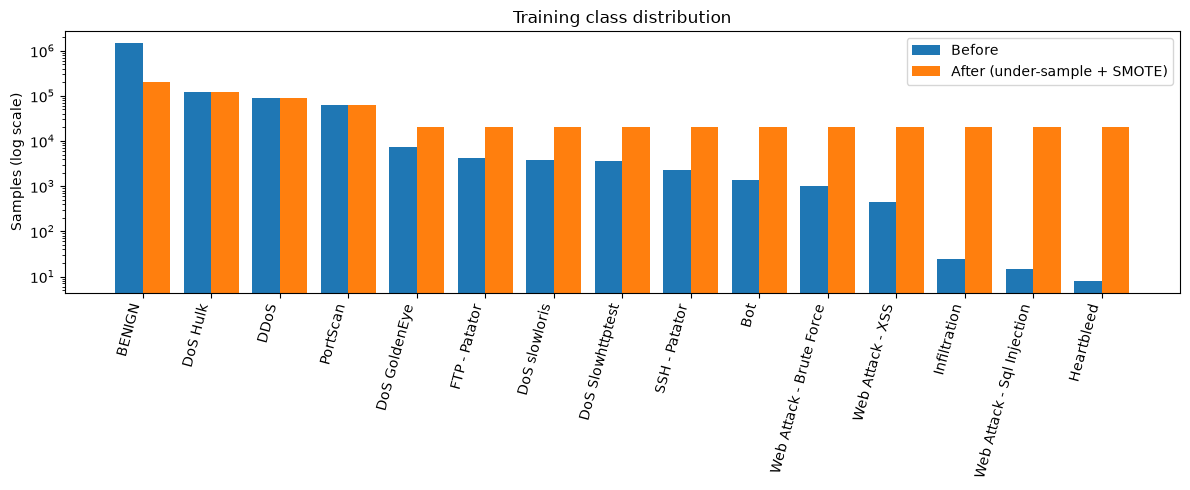

In [7]:
after = Counter(y_bal.tolist())
print(f"{'Class':35s} {'Before':>10s} {'After':>10s}")
for c in sorted(after, key=after.get, reverse=True):
    print(f"{class_names[c]:35s} {before.get(c,0):>10,} {after[c]:>10,}")

order = sorted(before, key=before.get, reverse=True)
x = np.arange(len(order)); w = 0.4
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, [before[c] for c in order], w, label="Before")
plt.bar(x + w/2, [after[c] for c in order], w, label="After (under-sample + SMOTE)")
plt.xticks(x, [class_names[c] for c in order], rotation=75, ha="right")
plt.yscale("log"); plt.ylabel("Samples (log scale)")
plt.title("Training class distribution"); plt.legend(); plt.tight_layout(); plt.show()

## Step 7: Save the balanced training set
Validation and test files from Phase 1 are **not** modified.

In [8]:
np.save(f"{DATA_DIR}/X_train_bal.npy", X_bal)
np.save(f"{DATA_DIR}/y_train_bal_multi.npy", y_bal)
np.save(f"{DATA_DIR}/y_train_bal_binary.npy", y_bal_binary)
print(sorted(f for f in os.listdir(DATA_DIR) if "bal" in f))
print("Phase 1b complete")

['X_train_bal.npy', 'y_train_bal_binary.npy', 'y_train_bal_multi.npy']
Phase 1b complete
